# Experiment 005: 0.5B base-to-GRPO analysis plots

This notebook checks `005_COLAB_FULL_B05_base_grpo_seed0`, trained on an A100 40 GB with
frozen protocol v1 and seed 0. The main comparison is paired base versus base+GRPO on the
same 1,884 MMLU test items.

The notebook also cross-checks experiment 004 for the A100 scale comparison, and experiments
002 and 003 for SFT context. The 002 comparison is descriptive only because it was a T4
protocol-development run. Figures are saved to `analysis/figures/005_1/` as 300 dpi PNG files.

In [ ]:
# find the repo root and load the saved results
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.py").exists():
    raise FileNotFoundError("I could not find the repository root containing config.py")
sys.path.insert(0, str(ROOT))

RES = ROOT / "results"
R2 = RES / "002_COLAB_FULL_B05_sft_grpo_seed0"
R3 = RES / "003_COLAB_FULL_B3_sft_grpo_seed0"
R4 = RES / "004_COLAB_FULL_B3_base_grpo_seed0"
B4 = RES / "base_evals" / "004_COLAB_FULL_B3"
R5 = RES / "005_COLAB_FULL_B05_base_grpo_seed0"
B5 = RES / "base_evals" / "005_COLAB_FULL_B05"
FIG = ROOT / "analysis" / "figures" / "005_1"
FIG.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"base": "#4C78A8", "grpo": "#F58518", "sft": "#54A24B", "other": "#B279A2"}

# keep these helpers small because most plots use them
def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def series(trainlog, key):
    rows = [row for row in trainlog if key in row and "step" in row]
    return np.asarray([row["step"] for row in rows]), np.asarray([row[key] for row in rows], dtype=float)

def smooth(values, window=20):
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

def overall(D, condition, probe=False):
    bucket = "lp_preds" if probe else "preds"
    return float(np.mean([row["correct"] for row in D[bucket][condition]]))

def edge_mean(log, key, first=True, count=50):
    values = [float(row[key]) for row in log if key in row and "step" in row]
    part = values[:count] if first else values[-count:]
    return float(np.mean(part))

def paired_correct(rows_a, rows_b, tier=None):
    if tier is not None:
        rows_a = [row for row in rows_a if row["tier"] == tier]
        rows_b = [row for row in rows_b if row["tier"] == tier]
    if len(rows_a) != len(rows_b):
        raise ValueError("I found different numbers of paired predictions")
    for a, b in zip(rows_a, rows_b):
        if (a["subject"], a["tier"], a["gold"]) != (b["subject"], b["tier"], b["gold"]):
            raise ValueError("I found predictions that are not aligned")
    return [bool(row["correct"]) for row in rows_a], [bool(row["correct"]) for row in rows_b]

def outcome_parts(rows):
    n = len(rows)
    return {
        "correct + full format": sum(row["correct"] and row["format_ok"] for row in rows) / n,
        "correct, no full format": sum(row["correct"] and not row["format_ok"] for row in rows) / n,
        "wrong but extracted": sum((not row["correct"]) and row["pred"] is not None for row in rows) / n,
        "no extracted answer": sum(row["pred"] is None for row in rows) / n,
    }

def load_base_grpo(run_dir, base_dir):
    return {
        "g": jload(run_dir / "grpo_trainlog.json"),
        "eval": {"base": jload(base_dir / "base_eval.json"), "grpo": jload(run_dir / "grpo_eval.json")},
        "lp": {"base": jload(base_dir / "base_logprob.json"), "grpo": jload(run_dir / "grpo_logprob.json")},
        "preds": {"base": jsonl(base_dir / "base_preds.jsonl"), "grpo": jsonl(run_dir / "grpo_preds.jsonl")},
        "lp_preds": {"base": jsonl(base_dir / "base_logprob_preds.jsonl"), "grpo": jsonl(run_dir / "grpo_logprob_preds.jsonl")},
        "man": jload(run_dir / "manifest.json"),
        "summary": jload(run_dir / "summary.json"),
    }

D5 = load_base_grpo(R5, B5)
D4 = load_base_grpo(R4, B4)
D2 = {
    "eval": {"grpo": jload(R2 / "grpo_eval.json")},
    "lp": {"grpo": jload(R2 / "grpo_logprob.json")},
    "preds": {"grpo": jsonl(R2 / "grpo_preds.jsonl")},
    "lp_preds": {"grpo": jsonl(R2 / "grpo_logprob_preds.jsonl")},
    "man": jload(R2 / "manifest.json"),
}
D3 = {
    "eval": {"grpo": jload(R3 / "grpo_eval.json")},
    "lp": {"grpo": jload(R3 / "grpo_logprob.json")},
    "preds": {"grpo": jsonl(R3 / "grpo_preds.jsonl")},
    "lp_preds": {"grpo": jsonl(R3 / "grpo_logprob_preds.jsonl")},
    "man": jload(R3 / "manifest.json"),
}

TIERS = ["easy", "medium", "hard"]
GROUPS = TIERS + ["overall"]
paired_correct(D5["preds"]["base"], D5["preds"]["grpo"])
assert len([row for row in D5["g"] if "reward" in row]) == 500
assert D5["eval"]["grpo"]["n_items"] == 1884
assert "A100" in D5["man"]["gpu"]["device"]
assert D5["man"]["git"]["dirty"] is False
print("loaded and checked experiment 005 artifacts")
print("figures ->", FIG)

loaded and checked experiment 005 artifacts
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/005_1


## 1. Run health

The run completed all planned stages. These checks separate a successful execution from the
scientific interpretation of the result.

In [ ]:
# put the main execution checks in one small table
train_rows = [row for row in D5["g"] if "reward" in row]
timings = D5["man"]["timings_sec"]
health_tbl = pd.DataFrame([{
    "completed_steps": len(train_rows),
    "eval_items": D5["eval"]["grpo"]["n_items"],
    "gpu": D5["man"]["gpu"]["device"],
    "peak_vram_gb": D5["man"]["gpu"]["peak_vram_gb"],
    "total_stage_hours": sum(timings.values()) / 3600,
    "git_commit": D5["man"]["git"]["commit"][:7],
    "git_clean": not D5["man"]["git"]["dirty"],
}]).round(3)
display(health_tbl)

,completed_steps,eval_items,gpu,peak_vram_gb,total_stage_hours,git_commit,git_clean
0,500,1884,NVIDIA A100-SXM4-40GB,21.644,6.279,0752f62,True


saved fig01_training_rewards


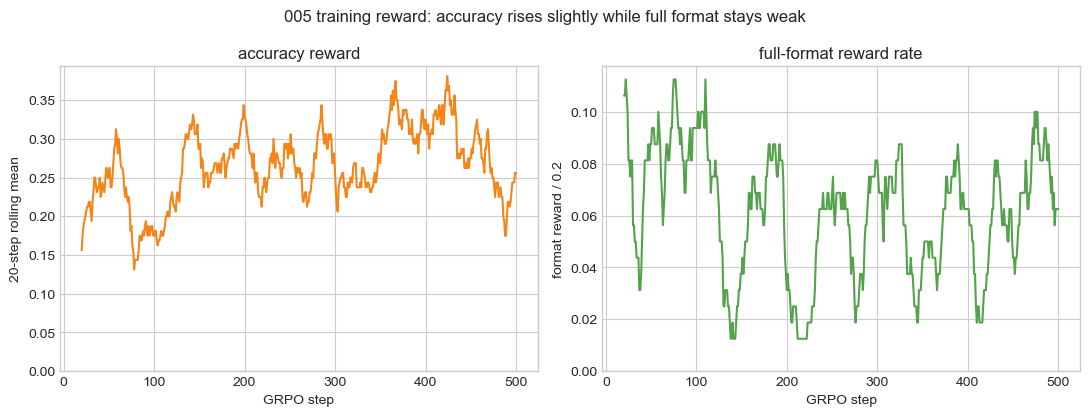

In [ ]:
# compare the two reward parts during training
window = 20
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x, accuracy = series(D5["g"], "rewards/accuracy_reward/mean")
axes[0].plot(x[window - 1:], smooth(accuracy, window), color=COLORS["grpo"])
x, format_reward = series(D5["g"], "rewards/format_reward/mean")
axes[1].plot(x[window - 1:], smooth(format_reward / 0.2, window), color=COLORS["sft"])
axes[0].set_title("accuracy reward")
axes[0].set_ylabel("20-step rolling mean")
axes[1].set_title("full-format reward rate")
axes[1].set_ylabel("format reward / 0.2")
for ax in axes:
    ax.set_xlabel("GRPO step")
    ax.set_ylim(bottom=0)
fig.suptitle("005 training reward: accuracy rises slightly while full format stays weak")
fig.tight_layout()
save(fig, "fig01_training_rewards")
plt.show()

saved fig02_kl_and_reward_variation


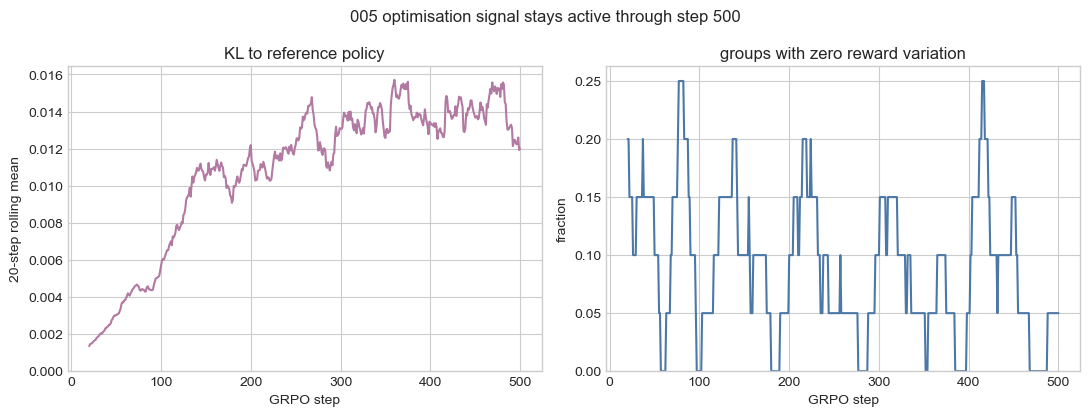

In [ ]:
# check whether the policy moved and whether reward groups still had variation
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x, kl = series(D5["g"], "kl")
axes[0].plot(x[window - 1:], smooth(kl, window), color=COLORS["other"])
x, zero_std = series(D5["g"], "frac_reward_zero_std")
axes[1].plot(x[window - 1:], smooth(zero_std, window), color=COLORS["base"])
axes[0].set_title("KL to reference policy")
axes[0].set_ylabel("20-step rolling mean")
axes[1].set_title("groups with zero reward variation")
axes[1].set_ylabel("fraction")
for ax in axes:
    ax.set_xlabel("GRPO step")
    ax.set_ylim(bottom=0)
fig.suptitle("005 optimisation signal stays active through step 500")
fig.tight_layout()
save(fig, "fig02_kl_and_reward_variation")
plt.show()

saved fig03_length_and_clipping


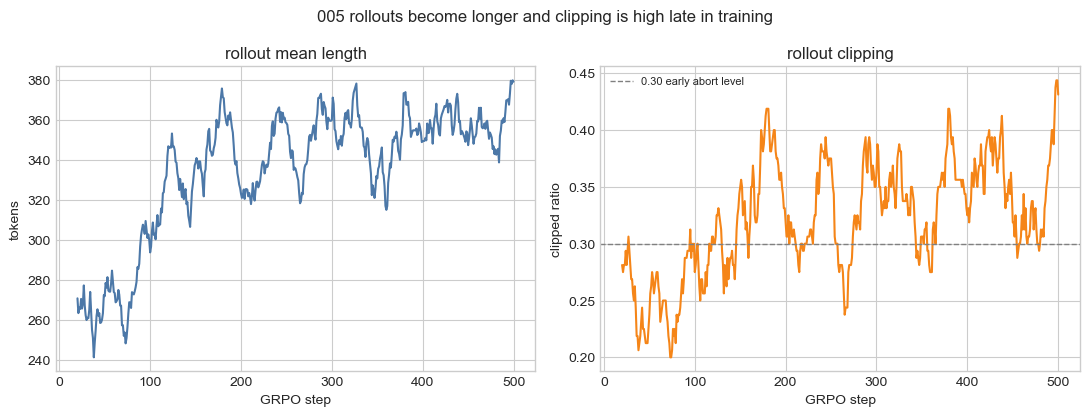

In [ ]:
# check lengths and clipping because the late rollouts look much longer
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x, lengths = series(D5["g"], "completions/mean_length")
axes[0].plot(x[window - 1:], smooth(lengths, window), color=COLORS["base"])
x, clipped = series(D5["g"], "completions/clipped_ratio")
axes[1].plot(x[window - 1:], smooth(clipped, window), color=COLORS["grpo"])
axes[1].axhline(0.3, color="grey", ls="--", lw=1, label="0.30 early abort level")
axes[0].set_title("rollout mean length")
axes[0].set_ylabel("tokens")
axes[1].set_title("rollout clipping")
axes[1].set_ylabel("clipped ratio")
for ax in axes:
    ax.set_xlabel("GRPO step")
axes[1].legend(fontsize=8)
fig.suptitle("005 rollouts become longer and clipping is high late in training")
fig.tight_layout()
save(fig, "fig03_length_and_clipping")
plt.show()

In [ ]:
# compare the first and last 50 steps instead of single noisy steps
training_rows = []
for key, label, scale in [
    ("rewards/accuracy_reward/mean", "accuracy reward", 1.0),
    ("rewards/format_reward/mean", "full-format reward rate", 0.2),
    ("kl", "KL", 1.0),
    ("completions/mean_length", "rollout mean length", 1.0),
    ("completions/clipped_ratio", "clipped ratio", 1.0),
    ("frac_reward_zero_std", "zero reward variation", 1.0),
]:
    first = edge_mean(D5["g"], key, first=True) / scale
    last = edge_mean(D5["g"], key, first=False) / scale
    training_rows.append({"metric": label, "first_50": first, "last_50": last, "change": last - first})
training_tbl = pd.DataFrame(training_rows).set_index("metric").round(4)
display(training_tbl)

,first_50,last_50,change
metric,,,
accuracy reward,0.2150,0.2550,0.0400
full-format reward rate,0.0850,0.0725,-0.0125
KL,0.0022,0.0138,0.0116
rollout mean length,265.3775,363.3175,97.9400
clipped ratio,0.2475,0.3625,0.1150
zero reward variation,0.1400,0.0200,-0.1200


## 2. Main endpoint result

The primary result is base versus base+GRPO inside experiment 005. The predictions are aligned
question by question, so paired confidence intervals and exact McNemar tests are appropriate.

saved fig04_endpoint_accuracy


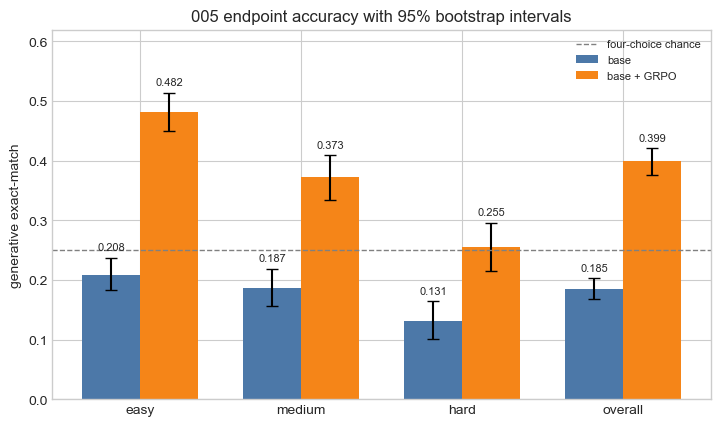

In [ ]:
# plot the saved bootstrap intervals for the two endpoints
xpos = np.arange(len(GROUPS))
width = 0.36
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for index, condition in enumerate(["base", "grpo"]):
    values = [D5["eval"][condition]["per_tier_acc"][tier] for tier in TIERS]
    values.append(overall(D5, condition))
    cis = [D5["eval"][condition]["per_tier_ci"][tier] for tier in TIERS]
    cis.append(D5["eval"][condition]["overall_ci"])
    errors = [[value - ci[0] for value, ci in zip(values, cis)],
              [ci[1] - value for value, ci in zip(values, cis)]]
    offset = (index - 0.5) * width
    bars = ax.bar(xpos + offset, values, width, yerr=errors, capsize=4,
                  label="base" if condition == "base" else "base + GRPO",
                  color=COLORS[condition])
    labels = [f"{value:.3f}" for value in values]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=8)
ax.axhline(0.25, color="grey", ls="--", lw=1, label="four-choice chance")
ax.set_xticks(xpos)
ax.set_xticklabels(GROUPS)
ax.set_ylim(0, 0.62)
ax.set_ylabel("generative exact-match")
ax.set_title("005 endpoint accuracy with 95% bootstrap intervals")
ax.legend(fontsize=8)
save(fig, "fig04_endpoint_accuracy")
plt.show()

In [ ]:
#calculate paired deltas and exact tests from the saved predictions
from analysis.stats import holm, mcnemar_exact, paired_delta_ci

paired_stats = []
for group in GROUPS:
    tier = None if group == "overall" else group
    base_correct, grpo_correct = paired_correct(D5["preds"]["base"], D5["preds"]["grpo"], tier=tier)
    delta, lo, hi = paired_delta_ci(base_correct, grpo_correct, seed=0)
    base_only = sum(a and not b for a, b in zip(base_correct, grpo_correct))
    grpo_only = sum((not a) and b for a, b in zip(base_correct, grpo_correct))
    paired_stats.append({
        "group": group,
        "delta": delta,
        "ci_lo": lo,
        "ci_hi": hi,
        "base_only": base_only,
        "grpo_only": grpo_only,
        "mcnemar_p": mcnemar_exact(base_only, grpo_only),
    })

#keep overall separate because it contains the same items as the three tiers
tier_adjusted = holm([row["mcnemar_p"] for row in paired_stats[:3]])
for row, adjusted in zip(paired_stats[:3], tier_adjusted):
    row["holm_p_tiers"] = adjusted
paired_stats[-1]["holm_p_tiers"] = np.nan

paired_tbl = pd.DataFrame(paired_stats).set_index("group")
display(paired_tbl.round({"delta": 4, "ci_lo": 4, "ci_hi": 4, "mcnemar_p": 8, "holm_p_tiers": 8}))

,delta,ci_lo,ci_hi,base_only,grpo_only,mcnemar_p,holm_p_tiers
group,,,,,,,
easy,0.2742,0.2332,0.3151,82,323,0.000000,0.000000
medium,0.1856,0.1379,0.2332,65,178,0.000000,0.000000
hard,0.1237,0.0732,0.1742,32,81,0.000005,0.000005
overall,0.2139,0.1868,0.2415,179,582,0.000000,NaN


saved fig05_paired_delta


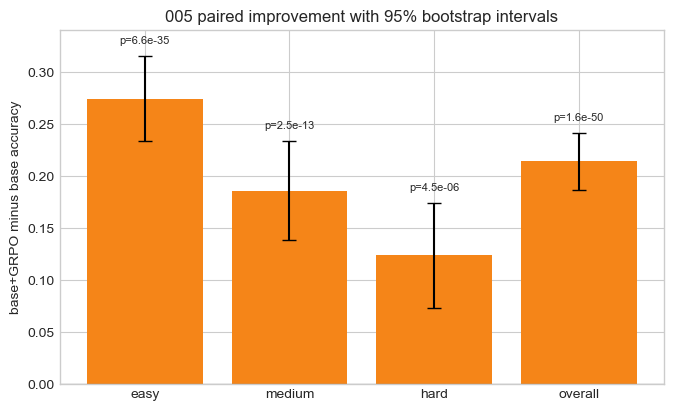

In [ ]:
# plot the paired improvement with its confidence interval
values = [row["delta"] for row in paired_stats]
errors = [[row["delta"] - row["ci_lo"] for row in paired_stats],
          [row["ci_hi"] - row["delta"] for row in paired_stats]]
fig, ax = plt.subplots(figsize=(7.8, 4.6))
bars = ax.bar(GROUPS, values, yerr=errors, capsize=5, color=COLORS["grpo"])
ax.axhline(0, color="black", lw=0.8)
for index, (bar, row) in enumerate(zip(bars, paired_stats)):
    ax.text(bar.get_x() + bar.get_width() / 2, row["ci_hi"] + 0.012,
            f"p={row['mcnemar_p']:.1e}", ha="center", fontsize=8)
ax.set_ylim(0, 0.34)
ax.set_ylabel("base+GRPO minus base accuracy")
ax.set_title("005 paired improvement with 95% bootstrap intervals")
save(fig, "fig05_paired_delta")
plt.show()

## 3. What changed

The log-probability probe tests the four answer letters without free-form generation. It stays
almost flat, so the large generative gain should be read as better answer production and
extraction, not as new encoded MMLU knowledge.

saved fig06_generation_vs_probe


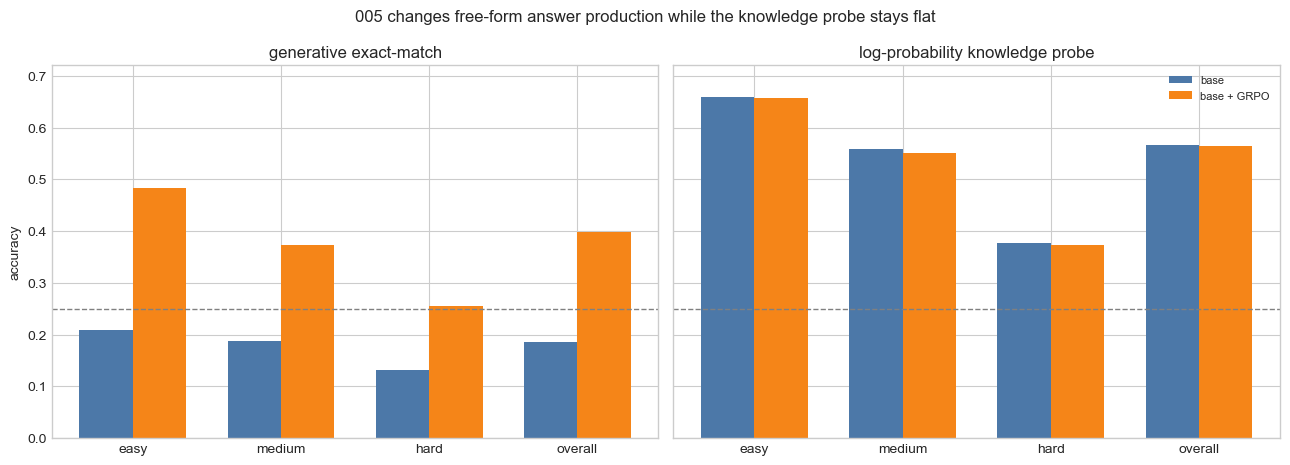

In [ ]:
# put generation and the knowledge probe on the same scale
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7), sharey=True)
for ax, probe, title in [
    (axes[0], False, "generative exact-match"),
    (axes[1], True, "log-probability knowledge probe"),
]:
    source = D5["lp"] if probe else D5["eval"]
    for index, condition in enumerate(["base", "grpo"]):
        values = [source[condition]["per_tier_acc"][tier] for tier in TIERS]
        values.append(overall(D5, condition, probe=probe))
        ax.bar(xpos + (index - 0.5) * width, values, width,
               label="base" if condition == "base" else "base + GRPO",
               color=COLORS[condition])
    ax.axhline(0.25, color="grey", ls="--", lw=1)
    ax.set_xticks(xpos)
    ax.set_xticklabels(GROUPS)
    ax.set_title(title)
    ax.set_ylim(0, 0.72)
axes[0].set_ylabel("accuracy")
axes[1].legend(fontsize=8)
fig.suptitle("005 changes free-form answer production while the knowledge probe stays flat")
fig.tight_layout()
save(fig, "fig06_generation_vs_probe")
plt.show()

saved fig07_eval_diagnostics


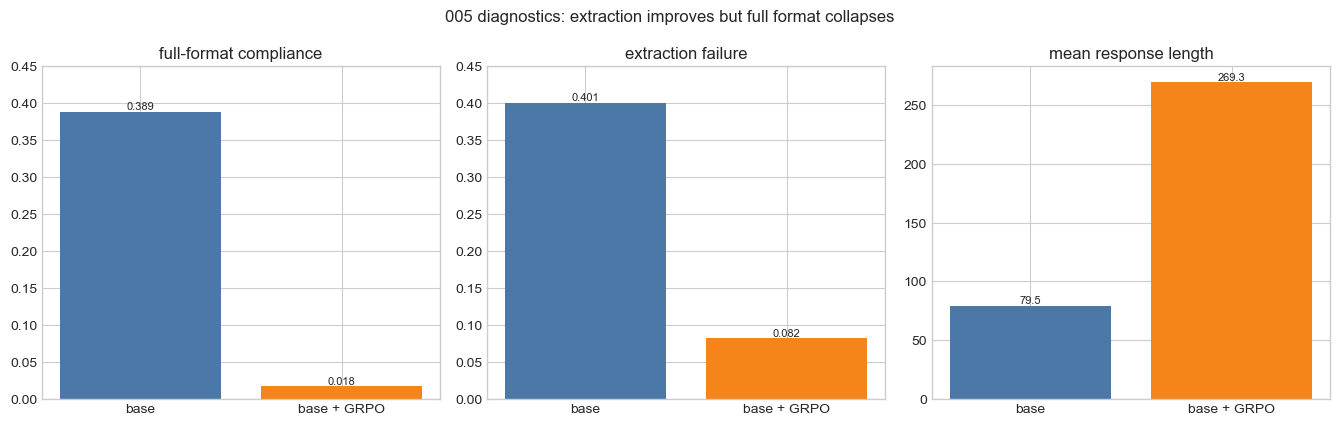

In [ ]:
# show the main evaluation warnings next to the accuracy result
metrics = [
    ("format_compliance", "full-format compliance", (0, 0.45)),
    ("extraction_failure_rate", "extraction failure", (0, 0.45)),
    ("mean_len", "mean response length", None),
]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
for ax, (key, title, limits) in zip(axes, metrics):
    values = [D5["eval"][condition][key] for condition in ["base", "grpo"]]
    bars = ax.bar(["base", "base + GRPO"], values,
                  color=[COLORS["base"], COLORS["grpo"]])
    for bar, value in zip(bars, values):
        label = f"{value:.1f}" if key == "mean_len" else f"{value:.3f}"
        ax.text(bar.get_x() + bar.get_width() / 2, value, label,
                ha="center", va="bottom", fontsize=8)
    ax.set_title(title)
    if limits:
        ax.set_ylim(*limits)
fig.suptitle("005 diagnostics: extraction improves but full format collapses")
fig.tight_layout()
save(fig, "fig07_eval_diagnostics")
plt.show()

saved fig08_answer_outcomes


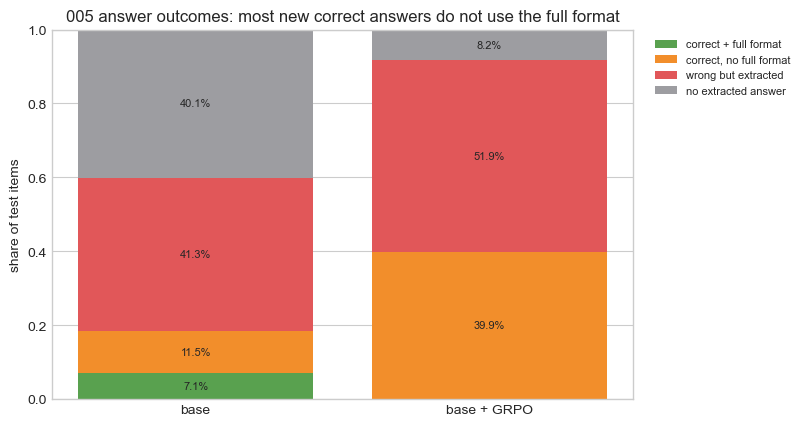

In [ ]:
# separate correct answers from formatting and extraction effects
parts = {condition: outcome_parts(D5["preds"][condition]) for condition in ["base", "grpo"]}
categories = list(parts["base"])
category_colors = ["#59A14F", "#F28E2B", "#E15759", "#9D9DA1"]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
bottom = np.zeros(2)
for category, color in zip(categories, category_colors):
    values = [parts[condition][category] for condition in ["base", "grpo"]]
    bars = ax.bar(["base", "base + GRPO"], values, bottom=bottom, label=category, color=color)
    for index, value in enumerate(values):
        if value >= 0.04:
            ax.text(index, bottom[index] + value / 2, f"{value:.1%}", ha="center", va="center", fontsize=8)
    bottom += values
ax.set_ylim(0, 1)
ax.set_ylabel("share of test items")
ax.set_title("005 answer outcomes: most new correct answers do not use the full format")
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
save(fig, "fig08_answer_outcomes")
plt.show()

saved fig09_subject_deltas


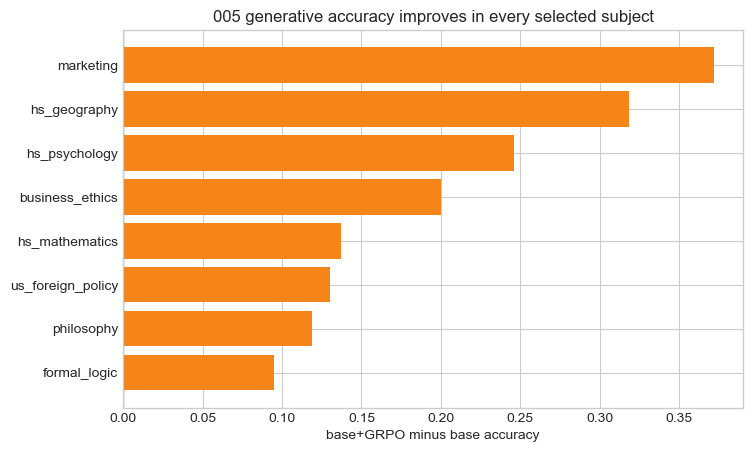

In [ ]:
# check whether the gain is limited to only a few subjects
subjects = list(D5["eval"]["base"]["per_subject_acc"])
subject_rows = []
for subject in subjects:
    base_value = D5["eval"]["base"]["per_subject_acc"][subject]
    grpo_value = D5["eval"]["grpo"]["per_subject_acc"][subject]
    subject_rows.append({"subject": subject, "base": base_value, "base_grpo": grpo_value,
                         "delta": grpo_value - base_value})
subject_tbl = pd.DataFrame(subject_rows).set_index("subject").sort_values("delta")
labels = [label.replace("high_school_", "hs_") for label in subject_tbl.index]
fig, ax = plt.subplots(figsize=(8, 4.9))
ax.barh(labels, subject_tbl["delta"], color=COLORS["grpo"])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("base+GRPO minus base accuracy")
ax.set_title("005 generative accuracy improves in every selected subject")
save(fig, "fig09_subject_deltas")
plt.show()

## 4. Cross-referenced comparisons

Experiments 004 and 005 both use the A100 family and BF16, although 004 used an 80 GB card and
005 used a 40 GB card. This makes the scale comparison much cleaner than T4 versus A100, but it
still has one seed per scale.

Experiment 002 is shown only as context. It used T4 FP16 and was involved in protocol selection,
so its difference from 005 cannot be attributed only to SFT.

saved fig10_base_grpo_by_scale


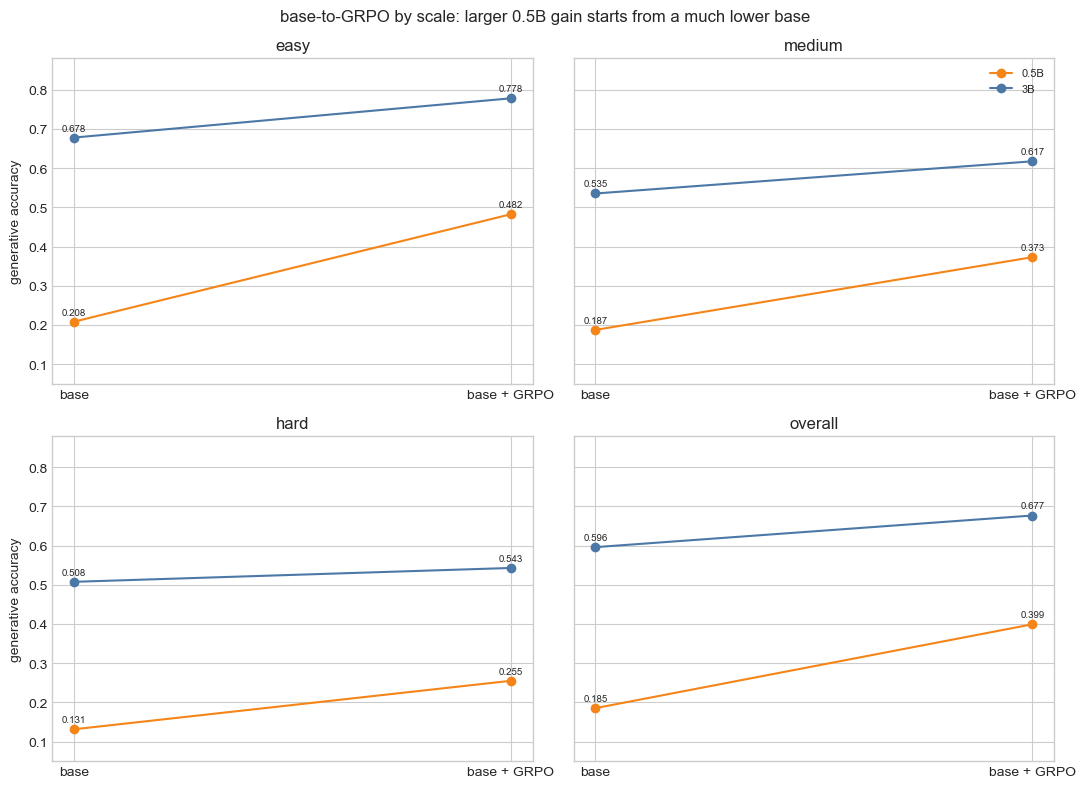

In [ ]:
# compare direct base-to-GRPO at 0.5B and 3B
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
for ax, group in zip(axes.flat, GROUPS):
    for D, label, color in [(D5, "0.5B", COLORS["grpo"]), (D4, "3B", COLORS["base"])]:
        if group == "overall":
            values = [overall(D, "base"), overall(D, "grpo")]
        else:
            values = [D["eval"][condition]["per_tier_acc"][group] for condition in ["base", "grpo"]]
        ax.plot([0, 1], values, "o-", label=label, color=color)
        for xpos_line, value in enumerate(values):
            ax.text(xpos_line, value + 0.018, f"{value:.3f}", ha="center", fontsize=7)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["base", "base + GRPO"])
    ax.set_title(group)
    ax.set_ylim(0.05, 0.88)
axes[0, 0].set_ylabel("generative accuracy")
axes[1, 0].set_ylabel("generative accuracy")
axes[0, 1].legend(fontsize=8)
fig.suptitle("base-to-GRPO by scale: larger 0.5B gain starts from a much lower base")
fig.tight_layout()
save(fig, "fig10_base_grpo_by_scale")
plt.show()

saved fig11_sft_context_by_scale


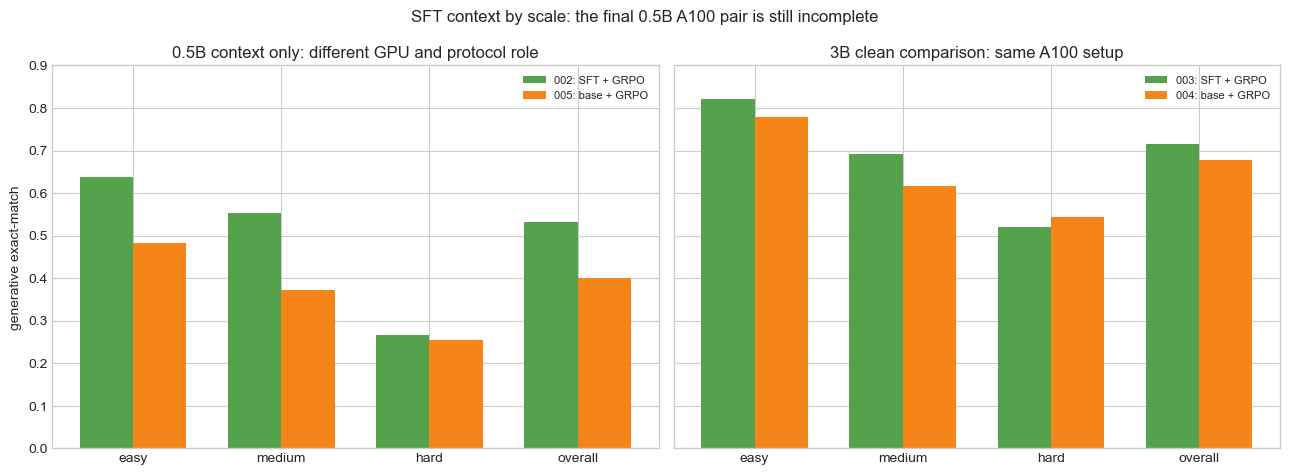

In [ ]:
# keep the old 0.5B comparison descriptive until the A100 rerun exists
def endpoint_values(D, condition):
    values = [D["eval"][condition]["per_tier_acc"][tier] for tier in TIERS]
    values.append(overall(D, condition))
    return values

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
comparisons = [
    (axes[0], [(D2, "grpo", "002: SFT + GRPO", COLORS["sft"]),
               (D5, "grpo", "005: base + GRPO", COLORS["grpo"])],
     "0.5B context only: different GPU and protocol role"),
    (axes[1], [(D3, "grpo", "003: SFT + GRPO", COLORS["sft"]),
               (D4, "grpo", "004: base + GRPO", COLORS["grpo"])],
     "3B clean comparison: same A100 setup"),
]
for ax, rows, title in comparisons:
    for index, (D, condition, label, color) in enumerate(rows):
        values = endpoint_values(D, condition)
        ax.bar(xpos + (index - 0.5) * width, values, width, label=label, color=color)
    ax.set_xticks(xpos)
    ax.set_xticklabels(GROUPS)
    ax.set_ylim(0, 0.9)
    ax.set_title(title)
    ax.legend(fontsize=8)
axes[0].set_ylabel("generative exact-match")
fig.suptitle("SFT context by scale: the final 0.5B A100 pair is still incomplete")
fig.tight_layout()
save(fig, "fig11_sft_context_by_scale")
plt.show()

saved fig12_compute_comparison


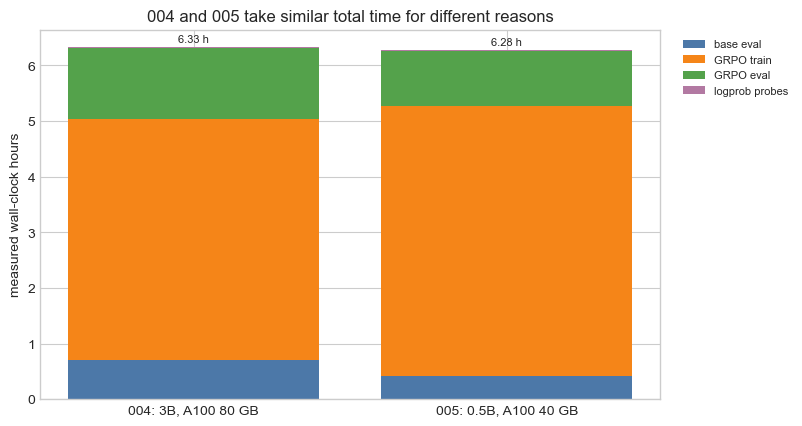

In [ ]:
# compare measured stage time without assuming model size is the only cause
stage_labels = ["base eval", "GRPO train", "GRPO eval", "logprob probes"]
fig, ax = plt.subplots(figsize=(8, 4.8))
bottom = np.zeros(2)
run_rows = [(D4, "004: 3B, A100 80 GB"), (D5, "005: 0.5B, A100 40 GB")]
for stage, color in zip(stage_labels, ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]):
    values = []
    for D, _ in run_rows:
        timing = D["man"]["timings_sec"]
        if stage == "base eval":
            seconds = timing.get("base_eval", 0)
        elif stage == "GRPO train":
            seconds = timing.get("grpo_train", 0)
        elif stage == "GRPO eval":
            seconds = timing.get("grpo_eval", 0)
        else:
            seconds = timing.get("base_logprob_eval", 0) + timing.get("grpo_logprob_eval", 0)
        values.append(seconds / 3600)
    ax.bar([row[1] for row in run_rows], values, bottom=bottom, label=stage, color=color)
    bottom += values
for index, total in enumerate(bottom):
    ax.text(index, total + 0.08, f"{total:.2f} h", ha="center", fontsize=8)
ax.set_ylabel("measured wall-clock hours")
ax.set_title("004 and 005 take similar total time for different reasons")
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
save(fig, "fig12_compute_comparison")
plt.show()

## 5. Numeric tables

In [ ]:
# keep generative and probe accuracy together for the main 005 result
accuracy_rows = []
for condition, label in [("base", "base"), ("grpo", "base + GRPO")]:
    row = {"condition": label}
    for tier in TIERS:
        row[f"gen_{tier}"] = D5["eval"][condition]["per_tier_acc"][tier]
        row[f"probe_{tier}"] = D5["lp"][condition]["per_tier_acc"][tier]
    row["gen_overall"] = overall(D5, condition)
    row["probe_overall"] = overall(D5, condition, probe=True)
    accuracy_rows.append(row)
accuracy_tbl = pd.DataFrame(accuracy_rows).set_index("condition").round(4)
display(accuracy_tbl)

,gen_easy,probe_easy,gen_medium,probe_medium,gen_hard,probe_hard,gen_overall,probe_overall
condition,,,,,,,,
base,0.2082,0.6587,0.1872,0.5583,0.1313,0.3763,0.1852,0.5669
base + GRPO,0.4824,0.6576,0.3727,0.5517,0.2551,0.3737,0.3992,0.5637


In [ ]:
# put format, extraction, length and the eval cap in one table
diagnostic_rows = []
for condition, label in [("base", "base"), ("grpo", "base + GRPO")]:
    rows = D5["preds"][condition]
    diagnostic_rows.append({
        "condition": label,
        "format_compliance": D5["eval"][condition]["format_compliance"],
        "extraction_failure": D5["eval"][condition]["extraction_failure_rate"],
        "mean_length": D5["eval"][condition]["mean_len"],
        "at_512_token_cap": np.mean([row["n_tokens"] >= 512 for row in rows]),
        "correct_and_full_format": np.mean([row["correct"] and row["format_ok"] for row in rows]),
    })
diagnostics_tbl = pd.DataFrame(diagnostic_rows).set_index("condition").round(4)
display(diagnostics_tbl)

,format_compliance,extraction_failure,mean_length,at_512_token_cap,correct_and_full_format
condition,,,,,
base,0.3891,0.4013,79.4501,0.0610,0.0706
base + GRPO,0.0175,0.0823,269.2792,0.0695,0.0005


In [ ]:
# keep the subject values behind the subject plot
subject_tbl = subject_tbl.round(4)
display(subject_tbl)

,base,base_grpo,delta
subject,,,
formal_logic,0.1984,0.2937,0.0952
philosophy,0.1961,0.3151,0.1190
us_foreign_policy,0.2800,0.4100,0.1300
high_school_mathematics,0.1000,0.2370,0.1370
business_ethics,0.1600,0.3600,0.2000
high_school_psychology,0.2220,0.4679,0.2459
high_school_geography,0.1263,0.4444,0.3182
marketing,0.1966,0.5684,0.3718


In [ ]:
# collect the four endpoint models used in the cross-reference
comparison_rows = []
for experiment, scale, route, D in [
    ("002", "0.5B", "SFT + GRPO", D2),
    ("005", "0.5B", "base + GRPO", D5),
    ("003", "3B", "SFT + GRPO", D3),
    ("004", "3B", "base + GRPO", D4),
]:
    row = {
        "experiment": experiment,
        "scale": scale,
        "route": route,
        "gpu": D["man"]["gpu"]["device"],
        "overall": overall(D, "grpo"),
        "format": D["eval"]["grpo"]["format_compliance"],
        "extraction_failure": D["eval"]["grpo"]["extraction_failure_rate"],
    }
    row.update({tier: D["eval"]["grpo"]["per_tier_acc"][tier] for tier in TIERS})
    comparison_rows.append(row)
comparison_tbl = pd.DataFrame(comparison_rows).set_index("experiment").round(4)
display(comparison_tbl)

,scale,route,gpu,overall,format,extraction_failure,easy,medium,hard
experiment,,,,,,,,,
002,0.5B,SFT + GRPO,Tesla T4,0.5324,0.7872,0.0430,0.6382,0.5534,0.2652
005,0.5B,base + GRPO,NVIDIA A100-SXM4-40GB,0.3992,0.0175,0.0823,0.4824,0.3727,0.2551
003,3B,SFT + GRPO,NVIDIA A100-SXM4-80GB,0.7160,0.9644,0.0297,0.8214,0.6913,0.5202
004,3B,base + GRPO,NVIDIA A100-SXM4-80GB,0.6768,0.9374,0.0494,0.7782,0.6174,0.5429


In [ ]:
# keep the measured stage times from the 005 manifest
compute_tbl = pd.DataFrame([
    {"stage": key, "seconds": value, "hours": value / 3600}
    for key, value in D5["man"]["timings_sec"].items()
]).set_index("stage")
compute_tbl.loc["total"] = [compute_tbl["seconds"].sum(), compute_tbl["hours"].sum()]
display(compute_tbl.round(3))

,seconds,hours
stage,,
base_eval,1473.902,0.409
base_logprob_eval,19.081,0.005
grpo_train,17501.433,4.862
grpo_eval,3587.559,0.997
grpo_logprob_eval,24.184,0.007
total,22606.159,6.279


## Cross-referenced conclusion

The run finished correctly and should be kept. It completed 500 steps, all 1,884 evaluation
items, used the frozen config, saved every expected artifact and stayed on A100 BF16.

The result is useful but it is not a clean format-learning success. Base+GRPO improves extracted
answer accuracy from 18.5% to 39.9% overall, and every tier and subject improves. The paired tests
are clearly significant. At the same time, the knowledge probe stays almost unchanged at about
56%, full-format compliance falls from 38.9% to 1.8%, and rollout clipping averages 36.3%
over the last 50 steps.
Most of the new correct answers are extracted from unformatted responses.

So the main interpretation is that direct GRPO helps the 0.5B model express and expose answers,
but it does not add measurable MMLU knowledge and it does not learn the full requested format.
This looks like a small-model limitation under the frozen reward balance, not a failed run or an
obvious code error. The larger GRPO gain than 3B partly comes from the much weaker 0.5B generative
base, so it should not be described as the 0.5B model benefiting more in an absolute sense.

Experiment 002 suggests that an SFT warm start may help 0.5B on easy and medium questions, but that
comparison is not clean because 002 used T4 FP16 and was a protocol-development run. The planned
A100 0.5B SFT+GRPO rerun is still needed before making the final RQ3 comparison at this scale.